# Introduction

Shoutout to Neel Nanda! I used his wonderful tutorial as a [reference](https://neelnanda.io/transformer-tutorial-2).

My version runs on CPU, since I don't have access to a GPU where I am currently living. When I get back home I will change it to run on GPU.

# Setup

In [9]:
!pip install torch transformers "huggingface_hub>=0.34,<1" "datasets>=2.16,<4" fancy_einsum einops plotly matplotlib
!pip install "easy_transformer @ git+https://github.com/neelnanda-io/Easy-Transformer.git@clean-transformer-demo"

  Cloning https://github.com/neelnanda-io/Easy-Transformer.git (to revision clean-transformer-demo) to /tmp/pip-install-4wwavz8s/easy-transformer_f978c82bd04243c1b0cc09550736caa9
  Running command git clone --filter=blob:none --quiet https://github.com/neelnanda-io/Easy-Transformer.git /tmp/pip-install-4wwavz8s/easy-transformer_f978c82bd04243c1b0cc09550736caa9
  Running command git checkout -b clean-transformer-demo --track origin/clean-transformer-demo
  Switched to a new branch 'clean-transformer-demo'
  branch 'clean-transformer-demo' set up to track 'origin/clean-transformer-demo'.
  Resolved https://github.com/neelnanda-io/Easy-Transformer.git to commit 1f25219e631aeb478d17075d47274db32c874e88
  Preparing metadata (setup.py) ... done


In [10]:
import sys
print(sys.executable)
print("Python", sys.version.split()[0])

/usr/bin/python3
Python 3.13.15


In [11]:
import einops
from fancy_einsum import einsum
from dataclasses import dataclass
from easy_transformer import EasyTransformer
import torch
import torch.nn as nn
import numpy as np
import math
from easy_transformer.utils import get_corner, gelu_new, tokenize_and_concatenate
import tqdm.auto as tqdm
import datasets

device = "cuda"

In [12]:
reference_gpt2 = EasyTransformer.from_pretrained(
    "gpt2-small",
    fold_ln=False,
    center_unembed=False,
    center_writing_weights=False,
    device=device,
)

Moving model to device:  cuda
Finished loading pretrained model gpt2-small into EasyTransformer!


# Actual Coding Time!

## Print All Activation Shapes of Reference Model

Key:
batch = 1
position = 35
d_model = 768
n_heads = 12
n_layers = 12
d_mlp = 3072 (4 * d_model)
d_head = 64

In [13]:
reference_text = "I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will exceed human level intelligence and take over the world!"
tokens = reference_gpt2.to_tokens(reference_text)
# print(tokens)
# print(tokens.shape)
# print(reference_gpt2.to_str_tokens(tokens))

tokens = tokens.to(device)
logits, cache = reference_gpt2.run_with_cache(tokens)
# print(logits.shape)

In [14]:
for activation_name, activation in cache.cache_dict.items():
    if ".0." in activation_name or "blocks" not in activation_name:
        print(activation_name, activation.shape)

hook_embed torch.Size([1, 35, 768])
hook_pos_embed torch.Size([1, 35, 768])
blocks.0.hook_resid_pre torch.Size([1, 35, 768])
blocks.0.ln1.hook_scale torch.Size([1, 35, 1])
blocks.0.ln1.hook_normalized torch.Size([1, 35, 768])
blocks.0.attn.hook_q torch.Size([1, 35, 12, 64])
blocks.0.attn.hook_k torch.Size([1, 35, 12, 64])
blocks.0.attn.hook_v torch.Size([1, 35, 12, 64])
blocks.0.attn.hook_attn_scores torch.Size([1, 12, 35, 35])
blocks.0.attn.hook_attn torch.Size([1, 12, 35, 35])
blocks.0.attn.hook_z torch.Size([1, 35, 12, 64])
blocks.0.hook_attn_out torch.Size([1, 35, 768])
blocks.0.hook_resid_mid torch.Size([1, 35, 768])
blocks.0.ln2.hook_scale torch.Size([1, 35, 1])
blocks.0.ln2.hook_normalized torch.Size([1, 35, 768])
blocks.0.mlp.hook_pre torch.Size([1, 35, 3072])
blocks.0.mlp.hook_post torch.Size([1, 35, 3072])
blocks.0.hook_mlp_out torch.Size([1, 35, 768])
blocks.0.hook_resid_post torch.Size([1, 35, 768])
ln_final.hook_scale torch.Size([1, 35, 1])
ln_final.hook_normalized torch.S

## Print All Parameters Shapes from the Reference Model

In [15]:
print(reference_gpt2)

EasyTransformer(
  (embed): Embed()
  (hook_embed): HookPoint()
  (pos_embed): PosEmbed()
  (hook_pos_embed): HookPoint()
  (blocks): ModuleList(
    (0-11): 12 x TransformerBlock(
      (ln1): LayerNorm(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (ln2): LayerNorm(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (attn): Attention(
        (hook_k): HookPoint()
        (hook_q): HookPoint()
        (hook_v): HookPoint()
        (hook_z): HookPoint()
        (hook_attn_scores): HookPoint()
        (hook_attn): HookPoint()
        (hook_result): HookPoint()
      )
      (mlp): MLP(
        (hook_pre): HookPoint()
        (hook_post): HookPoint()
      )
      (hook_attn_out): HookPoint()
      (hook_mlp_out): HookPoint()
      (hook_resid_pre): HookPoint()
      (hook_resid_mid): HookPoint()
      (hook_resid_post): HookPoint()
    )
  )
  (ln_final): LayerNorm(
    (hook_scale): HookPoint()
    (hook_norm

In [16]:
for name, param in reference_gpt2.named_parameters():
    if ".0." in name or "blocks" not in name:
        print(name, param.shape)

embed.W_E torch.Size([50257, 768])
pos_embed.W_pos torch.Size([1024, 768])
blocks.0.ln1.w torch.Size([768])
blocks.0.ln1.b torch.Size([768])
blocks.0.ln2.w torch.Size([768])
blocks.0.ln2.b torch.Size([768])
blocks.0.attn.W_Q torch.Size([12, 768, 64])
blocks.0.attn.W_K torch.Size([12, 768, 64])
blocks.0.attn.W_V torch.Size([12, 768, 64])
blocks.0.attn.W_O torch.Size([12, 64, 768])
blocks.0.attn.b_Q torch.Size([12, 64])
blocks.0.attn.b_K torch.Size([12, 64])
blocks.0.attn.b_V torch.Size([12, 64])
blocks.0.attn.b_O torch.Size([768])
blocks.0.mlp.W_in torch.Size([768, 3072])
blocks.0.mlp.b_in torch.Size([3072])
blocks.0.mlp.W_out torch.Size([3072, 768])
blocks.0.mlp.b_out torch.Size([768])
ln_final.w torch.Size([768])
ln_final.b torch.Size([768])
unembed.W_U torch.Size([768, 50257])
unembed.b_U torch.Size([50257])


## Config
for holding all params throughout the transformer

In [17]:
# printing reference model config - lots of useless stuff here (library internals, architectures etc)
print(reference_gpt2.cfg)

EasyTransformerConfig(n_layers=12, d_model=768, n_ctx=1024, d_head=64, model_name='gpt2-small', n_heads=12, d_mlp=3072, act_fn='gelu_new', d_vocab=50257, eps=1e-05, use_attn_result=False, use_attn_scale=True, use_local_attn=False, model_family='gpt2', checkpoint=None, tokenizer_name='gpt2', window_size=None, attn_types=None, init_mode='gpt2', normalization_type='LN', device='cuda', attention_dir='causal', attn_only=False, seed=42, initializer_range=np.float64(0.02886751345948129), init_weights=False, scale_attn_by_inverse_layer_idx=False, positional_embedding_type='standard', final_rms=False, d_vocab_out=50257, parallel_attn_mlp=False, rotary_dim=64, dtype=torch.float32)


In [18]:
@dataclass
class Config:
    d_model: int = 768
    debug: bool = False
    layer_norm_eps: float = 1e-5
    d_vocab: int = 50257
    init_range: float = 0.02
    n_ctx: int = 1024
    d_head: int = 64
    d_mlp: int = 3072
    n_heads: int = 12
    n_layers: int = 12


cfg = Config()
print(cfg)

Config(d_model=768, debug=True, layer_norm_eps=1e-05, d_vocab=50257, init_range=0.02, n_ctx=1024, d_head=64, d_mlp=3072, n_heads=12, n_layers=12)


## Tests

naive test: generate random inputs of the right shape, input to model, check for errors

In [31]:
def rand_float_test(cls, shape):
    cfg = Config(debug=True)
    layer = cls(cfg).to(device)
    random_input = torch.randn(shape, device=device)
    print("input: ", random_input.shape)
    output = layer(random_input)
    print("output: ", output.shape)
    print(get_corner(output))
    return output

def rand_int_test(cls, shape):
    cfg = Config(debug=True)
    layer = cls(cfg).to(device)
    random_input = torch.randint(100, 1000, shape)
    print("input: ", random_input.shape)
    output = layer(random_input)
    print("output: ", output.shape)
    print(get_corner(output))
    return output

def load_gpt2_test(cls, gpt2_layer, input_name, cache_dict=cache.cache_dict):
    cfg = Config(debug=True)
    layer = cls(cfg).to(device)
    layer.load_state_dict(gpt2_layer.state_dict(), strict=False)
    # Allow inputs of strings or tensors
    if isinstance(input_name, str):
        reference_input = cache_dict[input_name]
    else:
        reference_input = input_name
    print("Input shape:", reference_input.shape)
    output = layer(reference_input)
    print("Output shape:", output.shape)
    reference_output = gpt2_layer(reference_input)
    print("Reference output shape:", reference_output.shape)

    comparison = torch.isclose(output, reference_output, atol=1e-4, rtol=1e-3)
    print(f"{comparison.sum()/comparison.numel():.2%} of the values are correct")
    return output


## Layernorm

1. Make mean 0
2. Normalize to have variance 1
3. Scale with learned weights
4. Translate with learned bias

In [20]:
class LayerNorm(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.w = nn.Parameter(torch.ones(cfg.d_model))
        self.b = nn.Parameter(torch.zeros(cfg.d_model))

    def forward(self, residual):
        # residual: [batch, position, d_model]
        if cfg.debug:
            print(f"residual.shape: {residual.shape}")

        residual = residual - einops.reduce(residual, "batch position d_model -> batch position 1", "mean")

        # calculate the variance, square root it. add in an epsilon to prevent divide by zero
        scale = (einops.reduce(residual.pow(2), "batch position d_model -> batch position 1", "mean") + cfg.layer_norm_eps).sqrt()
        normalized = residual / scale
        normalized = normalized * self.w + self.b
        if cfg.debug:
            print("Normalized: ", residual.shape)
        return normalized

In [21]:
_ = rand_float_test(LayerNorm, (2, 4, 768))

input:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[ 1.8952,  1.4546,  0.8668],
         [ 0.3753, -3.1052, -1.4458],
         [-0.8698, -0.7143, -0.2062]],

        [[-0.9686, -1.0593, -0.6165],
         [-0.1416,  0.0713,  0.6640],
         [ 0.6808,  0.3704, -0.9783]]], grad_fn=<SliceBackward0>)


In [22]:
_ = load_gpt2_test(LayerNorm, reference_gpt2.ln_final, "blocks.11.hook_resid_post")

Input shape: torch.Size([1, 35, 768])
residual.shape: torch.Size([1, 35, 768])
Normalized:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are correct


## Embedding
Basically a lookup table from tokens to residual stream vectors.

In [23]:
class Embed(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_E = nn.Parameter(torch.empty((cfg.d_vocab, cfg.d_model)))
        nn.init.normal_(self.W_E, std=cfg.init_range)

    def forward(self, tokens):
        # tokens: [batch, position]
        if cfg.debug: print("Tokens: ", tokens.shape)
        embed = self.W_E[tokens, :] # [batch, position, d_model]
        if cfg.debug: print("Embeddings: ", embed.shape)
        return embed

rand_int_test(Embed, [2, 4])
load_gpt2_test(Embed, reference_gpt2.embed, tokens)

input:  torch.Size([2, 4])
Tokens:  torch.Size([2, 4])
Embeddings:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[-2.7572e-02,  5.5865e-03,  8.9741e-03],
         [ 1.1882e-02, -1.9358e-02,  2.0497e-02],
         [-7.9951e-05, -1.3304e-02,  1.7961e-02]],

        [[ 2.6705e-02,  1.4344e-02,  4.0169e-02],
         [ 2.4194e-02, -3.5725e-03, -4.6229e-03],
         [ 8.3898e-03,  2.2201e-02,  1.8022e-02]]], grad_fn=<SliceBackward0>)
Input shape: torch.Size([1, 35])
Tokens:  torch.Size([1, 35])
Embeddings:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are correct


tensor([[[ 0.0514, -0.0277,  0.0499,  ...,  0.0070,  0.1552,  0.1207],
         [ 0.1474, -0.0959,  0.1430,  ...,  0.1030, -0.0625, -0.1131],
         [ 0.1596, -0.1249,  0.1148,  ...,  0.2558,  0.0196,  0.0145],
         ...,
         [-0.0393,  0.0050,  0.0421,  ..., -0.0477,  0.0670, -0.0471],
         [-0.1488,  0.1519,  0.0056,  ..., -0.3107,  0.2073,  0.0377],
         [-0.1101, -0.0393,  0.0331,  ..., -0.1364,  0.0151,  0.0453]]],
       device='cuda:0', grad_fn=<IndexBackward0>)

## Positional Embedding
A learned vector for each position, added to the token embedding.

`W_pos` has shape `[n_ctx, d_model]` (`[1024, 768]`). Row `i` is the vector for position `i`. The token ids are ignored; only the sequence length is used. `forward` takes the first `position` rows, then repeats that table once per sequence in the batch. The output shape is `[batch, position, d_model]`.

In [24]:
class PosEmbed(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_pos = nn.Parameter(torch.empty((cfg.n_ctx, cfg.d_model)))
        nn.init.normal_(self.W_pos, std=cfg.init_range)

    def forward(self, tokens):
        # tokens: [batch, position]
        if cfg.debug: print("Tokens: ", tokens.shape)
        pos_embed = self.W_pos[:tokens.size(1), :] #  [position, d_model]
        pos_embed = einops.repeat(pos_embed, "position d_model -> batch position d_model", batch=tokens.size(0))
        if cfg.debug: print("Positional Embeddings: ", pos_embed.shape)
        return pos_embed

rand_int_test(PosEmbed, [2, 4])
load_gpt2_test(PosEmbed, reference_gpt2.pos_embed, tokens)


input:  torch.Size([2, 4])
Tokens:  torch.Size([2, 4])
Positional Embeddings:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[ 0.0079,  0.0193, -0.0160],
         [ 0.0285, -0.0080, -0.0085],
         [-0.0117, -0.0007,  0.0124]],

        [[ 0.0079,  0.0193, -0.0160],
         [ 0.0285, -0.0080, -0.0085],
         [-0.0117, -0.0007,  0.0124]]], grad_fn=<SliceBackward0>)
Input shape: torch.Size([1, 35])
Tokens:  torch.Size([1, 35])
Positional Embeddings:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are correct


tensor([[[-1.8821e-02, -1.9742e-01,  4.0267e-03,  ..., -4.3044e-02,
           2.8267e-02,  5.4490e-02],
         [ 2.3959e-02, -5.3792e-02, -9.4879e-02,  ...,  3.4170e-02,
           1.0172e-02, -1.5573e-04],
         [ 4.2161e-03, -8.4764e-02,  5.4515e-02,  ...,  1.9745e-02,
           1.9325e-02, -2.1424e-02],
         ...,
         [ 4.6277e-04,  2.3037e-02,  4.1227e-02,  ..., -1.9287e-03,
          -2.3037e-03, -4.3189e-03],
         [-2.7136e-03,  2.1724e-02,  3.9675e-02,  ...,  4.2048e-04,
          -4.8160e-03, -9.2252e-04],
         [ 6.6815e-03,  2.0595e-02,  3.6596e-02,  ..., -9.5090e-04,
          -3.2512e-03, -9.6509e-04]]], device='cuda:0',
       grad_fn=<ExpandBackward0>)

## Attention
* Step 1: Produce an attention pattern : for each destination token, probability distribution over previous tokens (incl. current token)
    * Linear map from input -> query, key shape [batch, position, head_index, d_head]
    * Dot product every *pair* of queries and keys to get attn_scores [batch, head_index, query_pos, key_pos] (query = dest, key = source)
    * Scale and mask attn_scores to make it lower triangular (causal masking)
    * Softmax row-wise, to get a probability distribution along each of they key_pos dimension - this is our attention pattern!

* Step 2: Move information from source tokens to destination token using attention pattern (move = apply linear map)
    * Linear map from input -> value [batch, key_pos, head_index, d_head]
    * Mix along the key_pos with attn pattern to get z, a mixed value [batch, query_pos, head_index, d_head]
    * Map to output, [batch, position, d_model] (position = query_pos, we've summed over all heads)

In [55]:
class Attention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_Q = nn.Parameter(torch.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        nn.init.normal_(self.W_Q, std=cfg.init_range)
        self.b_Q = nn.Parameter(torch.zeros((cfg.n_heads, cfg.d_head)))
        self.W_K = nn.Parameter(torch.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        nn.init.normal_(self.W_K, std=cfg.init_range)
        self.b_K = nn.Parameter(torch.zeros((cfg.n_heads, cfg.d_head)))
        self.W_V = nn.Parameter(torch.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        nn.init.normal_(self.W_V, std=cfg.init_range)
        self.b_V = nn.Parameter(torch.zeros((cfg.n_heads, cfg.d_head)))

        self.W_O = nn.Parameter(torch.empty((cfg.n_heads, cfg.d_head, cfg.d_model)))
        nn.init.normal_(self.W_O, std=cfg.init_range)
        self.b_O = nn.Parameter(torch.zeros((cfg.d_model)))

        self.register_buffer("IGNORE", torch.tensor(-1e5, dtype=torch.float32, device=device))

    def forward(self, normalized_resid_pre):
        if cfg.debug: print("normalized_resid_pre: ", normalized_resid_pre.shape)

        q = einsum("batch query_pos d_model, n_heads d_model d_head -> batch query_pos n_heads d_head", normalized_resid_pre, self.W_Q) + self.b_Q
        k = einsum("batch key_pos d_model, n_heads d_model d_head -> batch key_pos n_heads d_head", normalized_resid_pre, self.W_K) + self.b_K

        attn_scores = einsum("batch query_pos n_heads d_head, batch key_pos n_heads d_head -> batch n_heads query_pos key_pos", q, k)
        attn_scores = attn_scores / math.sqrt(self.cfg.d_head)
        attn_scores = self.apply_causal_mask(attn_scores)

        attn = attn_scores.softmax(dim=-1) # [batch, n_heads, query_pos, key_pos]

        v = einsum("batch key_pos d_model, n_heads d_model d_head -> batch key_pos n_heads d_head", normalized_resid_pre, self.W_V) + self.b_V

        z = einsum("batch n_heads query_pos key_pos, batch key_pos n_heads d_head -> batch query_pos n_heads d_head", attn, v)

        attn_out = einsum("batch query_pos n_heads d_head, n_heads d_head d_model -> batch query_pos d_model", z, self.W_O) + self.b_O
        return attn_out

    def apply_causal_mask(self, attn_scores):
        # attn_scores: [batch, n_heads, query_pos, key_pos]
        mask = torch.triu(torch.ones(attn_scores.size(-2), attn_scores.size(-1), device=attn_scores.device), diagonal=1).bool()
        attn_scores.masked_fill_(mask, -1e5)
        return attn_scores

rand_float_test(Attention, [2, 4, 768])
load_gpt2_test(Attention, reference_gpt2.blocks[0].attn, cache["blocks.0.ln1.hook_normalized"])

Exception ignored in: <_io.BytesIO object at 0x7c1670018810>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7c1670019120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x7c1670019170>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO ob

input:  torch.Size([2, 4, 768])
normalized_resid_pre:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[-0.1267,  0.0144, -0.1031],
         [-0.3251,  0.0843,  0.0312],
         [-0.2753,  0.0064, -0.0286]],

        [[-0.0040,  0.1842,  0.0499],
         [-0.1287, -0.3119, -0.0316],
         [-0.3035, -0.1589,  0.0183]]], device='cuda:0',
       grad_fn=<SliceBackward0>)
Input shape: torch.Size([1, 35, 768])
normalized_resid_pre:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are correct


tensor([[[ 7.9663e-01,  1.6986e-02,  3.4781e-02,  ...,  3.3120e-02,
          -2.3129e-02,  1.8103e-01],
         [ 1.3165e-03,  1.5750e-01, -1.4059e-01,  ..., -8.1997e-03,
           5.3075e-03,  1.3511e-01],
         [ 8.9738e-02, -7.2411e-01, -6.9866e-01,  ...,  5.5321e-02,
           2.7958e-03,  9.0785e-02],
         ...,
         [-3.0286e-01,  4.9638e-02, -6.0990e-01,  ..., -3.7084e-02,
          -4.9525e-04, -8.6008e-03],
         [-1.0844e+00, -6.1457e-02,  2.2966e-01,  ..., -2.6688e-02,
          -1.4368e-02,  3.3245e-02],
         [ 3.7947e-01, -4.9886e-01,  2.6434e-01,  ..., -2.7894e-02,
          -8.9028e-03,  4.8796e-02]]], device='cuda:0', grad_fn=<AddBackward0>)

In [33]:
reference_gpt2.blocks[0].attn

Attention(
  (hook_k): HookPoint()
  (hook_q): HookPoint()
  (hook_v): HookPoint()
  (hook_z): HookPoint()
  (hook_attn_scores): HookPoint()
  (hook_attn): HookPoint()
  (hook_result): HookPoint()
)

## MLP

In [34]:
class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_in = nn.Parameter(torch.empty((cfg.d_model, cfg.d_mlp)))
        nn.init.normal_(self.W_in, std=self.cfg.init_range)
        self.b_in = nn.Parameter(torch.zeros(cfg.d_mlp))
        nn.init.normal_(self.W_in, std=self.cfg.init_range)
        self.b_in = nn.Parameter(torch.zeros(cfg.d_mlp))
        self.W_out = nn.Parameter(torch.empty((cfg.d_mlp, cfg.d_model)))
        nn.init.normal_(self.W_out, std=self.cfg.init_range)
        self.b_out = nn.Parameter(torch.zeros(cfg.d_model))

    def forward(self, normalized_resid_mid):
        if cfg.debug: print("normalized_resid_mid: ", normalized_resid_mid.shape)

        pre = einsum("batch position d_model, d_model d_mlp -> batch position d_mlp", normalized_resid_mid, self.W_in) + self.b_in
        post = gelu_new(pre)
        mlp_out = einsum("batch position d_mlp, d_mlp d_model -> batch position d_model", post, self.W_out) + self.b_out
        return mlp_out

rand_float_test(MLP, [2, 4, 768])
load_gpt2_test(MLP, reference_gpt2.blocks[0].mlp, cache["blocks.0.ln2.hook_normalized"])
reference_gpt2.blocks[0].mlp

input:  torch.Size([2, 4, 768])
normalized_resid_mid:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[-0.0331,  0.8701, -0.2572],
         [-0.4222, -0.0069, -0.1511],
         [-0.0652,  0.1189,  0.4298]],

        [[ 0.1737,  0.1438, -0.3125],
         [ 0.4577,  0.5694,  0.0851],
         [ 0.5539,  0.1011, -0.2735]]], device='cuda:0',
       grad_fn=<SliceBackward0>)
Input shape: torch.Size([1, 35, 768])
normalized_resid_mid:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are correct


MLP(
  (hook_pre): HookPoint()
  (hook_post): HookPoint()
)

## Transformer Block

In [35]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg

        self.ln1 = LayerNorm(cfg)
        self.attn = Attention(cfg)
        self.ln2 = LayerNorm(cfg)
        self.mlp = MLP(cfg)

    def forward(self, resid_pre):
        # resid_pre [batch, position, d_model]
        normalized_resid_pre = self.ln1(resid_pre)
        attn_out = self.attn(normalized_resid_pre)
        resid_mid = resid_pre + attn_out

        normalized_resid_mid = self.ln2(resid_mid)
        mlp_out = self.mlp(normalized_resid_mid)
        resid_post = resid_mid + mlp_out
        return resid_post

rand_float_test(TransformerBlock, [2, 4, 768])
load_gpt2_test(TransformerBlock, reference_gpt2.blocks[0], cache["resid_pre", 0])
reference_gpt2.blocks[0]

input:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_pre:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_mid:  torch.Size([2, 4, 768])
output:  torch.Size([2, 4, 768])
tensor([[[-1.4130, -0.2599, -0.1403],
         [-1.0674, -1.9939,  1.5957],
         [ 2.5255,  1.6715,  0.4608]],

        [[-0.5349, -2.0229, -0.8990],
         [-0.6687, -0.3781, -0.9011],
         [ 1.0387, -0.0407, -0.7712]]], device='cuda:0',
       grad_fn=<SliceBackward0>)
Input shape: torch.Size([1, 35, 768])
residual.shape: torch.Size([1, 35, 768])
Normalized:  torch.Size([1, 35, 768])
normalized_resid_pre:  torch.Size([1, 35, 768])
residual.shape: torch.Size([1, 35, 768])
Normalized:  torch.Size([1, 35, 768])
normalized_resid_mid:  torch.Size([1, 35, 768])
Output shape: torch.Size([1, 35, 768])
Reference output shape: torch.Size([1, 35, 768])
100.00% of the values are

TransformerBlock(
  (ln1): LayerNorm(
    (hook_scale): HookPoint()
    (hook_normalized): HookPoint()
  )
  (ln2): LayerNorm(
    (hook_scale): HookPoint()
    (hook_normalized): HookPoint()
  )
  (attn): Attention(
    (hook_k): HookPoint()
    (hook_q): HookPoint()
    (hook_v): HookPoint()
    (hook_z): HookPoint()
    (hook_attn_scores): HookPoint()
    (hook_attn): HookPoint()
    (hook_result): HookPoint()
  )
  (mlp): MLP(
    (hook_pre): HookPoint()
    (hook_post): HookPoint()
  )
  (hook_attn_out): HookPoint()
  (hook_mlp_out): HookPoint()
  (hook_resid_pre): HookPoint()
  (hook_resid_mid): HookPoint()
  (hook_resid_post): HookPoint()
)

## Unembedding

In [36]:
class Unembed(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_U = nn.Parameter(torch.empty((cfg.d_model, cfg.d_vocab)))
        nn.init.normal_(self.W_U, std=cfg.init_range)
        self.b_U = nn.Parameter(torch.zeros(cfg.d_vocab), requires_grad=False)

    def forward(self, normalized_resid_final):
        # normalized_resid_final [batch, position, d_model]
        if cfg.debug: print("normalized_resid_final: ", normalized_resid_final.shape)
        logits = einsum("batch position d_model, d_model d_vocab -> batch position d_vocab", normalized_resid_final, self.W_U) + self.b_U
        return logits

print(cache)
rand_float_test(Unembed, [2, 4, 768])
load_gpt2_test(Unembed, reference_gpt2.unembed, cache["ln_final.hook_normalized"])
reference_gpt2.unembed

ActivationCache with keys ['hook_embed', 'hook_pos_embed', 'blocks.0.hook_resid_pre', 'blocks.0.ln1.hook_scale', 'blocks.0.ln1.hook_normalized', 'blocks.0.attn.hook_q', 'blocks.0.attn.hook_k', 'blocks.0.attn.hook_v', 'blocks.0.attn.hook_attn_scores', 'blocks.0.attn.hook_attn', 'blocks.0.attn.hook_z', 'blocks.0.hook_attn_out', 'blocks.0.hook_resid_mid', 'blocks.0.ln2.hook_scale', 'blocks.0.ln2.hook_normalized', 'blocks.0.mlp.hook_pre', 'blocks.0.mlp.hook_post', 'blocks.0.hook_mlp_out', 'blocks.0.hook_resid_post', 'blocks.1.hook_resid_pre', 'blocks.1.ln1.hook_scale', 'blocks.1.ln1.hook_normalized', 'blocks.1.attn.hook_q', 'blocks.1.attn.hook_k', 'blocks.1.attn.hook_v', 'blocks.1.attn.hook_attn_scores', 'blocks.1.attn.hook_attn', 'blocks.1.attn.hook_z', 'blocks.1.hook_attn_out', 'blocks.1.hook_resid_mid', 'blocks.1.ln2.hook_scale', 'blocks.1.ln2.hook_normalized', 'blocks.1.mlp.hook_pre', 'blocks.1.mlp.hook_post', 'blocks.1.hook_mlp_out', 'blocks.1.hook_resid_post', 'blocks.2.hook_resid_pr

Unembed()

## Full Transformer

In [37]:
class DemoTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.embed = Embed(cfg)
        self.pos_embed = PosEmbed(cfg)
        self.blocks = nn.ModuleList([TransformerBlock(cfg) for _ in range(cfg.n_layers)])
        self.ln_final = LayerNorm(cfg)
        self.unembed = Unembed(cfg)

    def forward(self, tokens):
        # tokens: [batch, position]

        # embeddings + poisttional embeddings
        embed = self.embed(tokens)
        pos_embed = self.pos_embed(tokens)
        residual = embed + pos_embed

        for block in self.blocks:
            residual = block(residual)
        normalized_resid_final = self.ln_final(residual)
        logits = self.unembed(normalized_resid_final)

        return logits

rand_int_test(DemoTransformer, [2, 4])
load_gpt2_test(DemoTransformer, reference_gpt2, tokens)

input:  torch.Size([2, 4])
Tokens:  torch.Size([2, 4])
Embeddings:  torch.Size([2, 4, 768])
Tokens:  torch.Size([2, 4])
Positional Embeddings:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_pre:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_mid:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_pre:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_mid:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_pre:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_resid_mid:  torch.Size([2, 4, 768])
residual.shape: torch.Size([2, 4, 768])
Normalized:  torch.Size([2, 4, 768])
normalized_

tensor([[[ -43.4317,  -39.8364,  -43.0660,  ...,  -54.0878,  -54.3452,
           -42.3644],
         [-128.0392, -127.9936, -130.7010,  ..., -136.7121, -129.9261,
          -129.3965],
         [-119.8521, -121.0064, -123.8820,  ..., -128.5180, -126.6027,
          -121.9060],
         ...,
         [-112.9815, -112.7749, -117.0633,  ..., -121.2914, -117.6574,
          -114.5005],
         [ -98.6724, -104.4888, -108.7361,  ..., -118.3552, -113.8766,
          -106.3604],
         [-126.8285, -128.9596, -128.3941,  ..., -140.1970, -138.5883,
          -122.3697]]], device='cuda:0', grad_fn=<AddBackward0>)

## Testing out our model with pre-trained weights

In [38]:
demo_gpt2 = DemoTransformer(Config(debug=False))
demo_gpt2.load_state_dict(reference_gpt2.state_dict(), strict=False)

_IncompatibleKeys(missing_keys=[], unexpected_keys=['blocks.0.attn.mask', 'blocks.1.attn.mask', 'blocks.2.attn.mask', 'blocks.3.attn.mask', 'blocks.4.attn.mask', 'blocks.5.attn.mask', 'blocks.6.attn.mask', 'blocks.7.attn.mask', 'blocks.8.attn.mask', 'blocks.9.attn.mask', 'blocks.10.attn.mask', 'blocks.11.attn.mask'])

test string - a random wikipedia article

In [39]:
test_string = """Mini scule is a species of microhylid frog endemic to Madagascar that was described in 2019. The scientific name of the species refers to its size, being a pun on the word minuscule. It is very small, measuring only 8.4 to 10.8 mm (0.33 to 0.43 in) in snout–vent length. It has bronze underparts with a brown groin and back of the thigh, cream upperparts with brown flecking, a dark brown side of the head, and a red iris. On the hind feet, the first toe is absent and the second and fifth toes are strongly reduced. The frog is known only from the Sainte Luce Reserve, where it inhabits areas with deep leaf litter near semi-permanent water bodies. Specimens of frogs from Mandena, the Vohimena mountains, the southern Anosy Mountains, and Tsitongambarika may also be of this species. Along with Mini mum and Mini ature, the other two species in its genus, it received media attention when first described due to the wordplay in its scientific name. (Full article...)"""

In [41]:
test_tokens = reference_gpt2.to_tokens(test_string)
demo_logits = demo_gpt2(test_tokens)

Tokens:  torch.Size([1, 237])
Embeddings:  torch.Size([1, 237, 768])
Tokens:  torch.Size([1, 237])
Positional Embeddings:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_pre:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_mid:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_pre:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_mid:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_pre:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 237, 768])
normalized_resid_mid:  torch.Size([1, 237, 768])
residual.shape: torch.Size([1, 237, 768])
Normalized:  torch.Size([1, 2

In [42]:
def lm_cross_entropy_loss(logits, tokens):
    # measure next token loss
    # logits have shape [batch, position, d_vocab]
    # tokens have shape [batch, position]
    log_probs = logits.log_softmax(dim=-1)
    pred_log_probs = log_probs[:, :-1].gather(dim=-1, index=tokens[:, 1:].unsqueeze(-1)).squeeze(-1)
    return -pred_log_probs.mean()

loss = lm_cross_entropy_loss(demo_logits, test_tokens)
print(loss)
print("Loss as average prob", (-loss).exp())
print("Loss as 'uniform over this many variables'", (loss).exp())
print("Uniform loss over the vocab", math.log(demo_gpt2.cfg.d_vocab))

tensor(3.7186, grad_fn=<NegBackward0>)
Loss as average prob tensor(0.0243, grad_fn=<ExpBackward0>)
Loss as 'uniform over this many variables' tensor(41.2077, grad_fn=<ExpBackward0>)
Uniform loss over the vocab 10.82490511970208


In [ ]:
temperature = 0.8
test_string = "My name is chatGPT. I am a "
for i in tqdm.tqdm(range(100)):
    test_tokens = reference_gpt2.to_tokens(test_string)
    demo_logits = demo_gpt2(test_tokens)
    probs = (demo_logits[-1, -1] / temperature).softmax(dim=-1)
    next_id = torch.multinomial(probs, num_samples=1)
    test_string += reference_gpt2.tokenizer.decode(next_id)

In [44]:
print(test_string)

My name is chatGPT. I am a vernacular speak-in speaker and can speak in English (Chinese, Farsi, Arabic, etc.). I also speak Hindi for all languages.


What is your favorite part of learning English? I learn this with friends as well, and it just takes me back to other parts of my life.


What is your favorite part of speaking Spanish? I learned this with friends as well, and it just takes me back to other parts of my life.


Do you like


## Training our model

## Config

In [59]:
batch_size = 8
num_epochs = 1
log_every = 10
lr = 1e-3
weight_decay = 1e-2

model_cfg = Config(debug=False, d_model=256, n_heads=4, d_head=64, d_mlp=1024, n_layers=2, n_ctx=256,d_vocab=reference_gpt2.cfg.d_vocab)

## Loading Data

In [60]:
dataset = datasets.load_dataset("NeelNanda/pile-10k", split="train")
print(dataset)
print(dataset[0])

Dataset({
    features: ['text', 'meta'],
    num_rows: 10000
})
{'text': 'It is done, and submitted. You can play “Survival of the Tastiest” on Android, and on the web. Playing on the web works, but you have to simulate multi-touch for table moving and that can be a bit confusing.\n\nThere’s a lot I’d like to talk about. I’ll go through every topic, insted of making the typical what went right/wrong list.\n\nConcept\n\nWorking over the theme was probably one of the hardest tasks I had to face.\n\nOriginally, I had an idea of what kind of game I wanted to develop, gameplay wise – something with lots of enemies/actors, simple graphics, maybe set in space, controlled from a top-down view. I was confident I could fit any theme around it.\n\nIn the end, the problem with a theme like “Evolution” in a game is that evolution is unassisted. It happens through several seemingly random mutations over time, with the most apt permutation surviving. This genetic car simulator is, in my opinion, a g

In [61]:
tokens_dataset = tokenize_and_concatenate(dataset, reference_gpt2.tokenizer,
streaming=False, max_length=model_cfg.n_ctx, column_name="text", add_bos_token=True, num_proc=4)

import torchvision.io as tio
if not hasattr(tio, "VideoReader"):
    class VideoReader:
        pass
    tio.VideoReader = VideoReader

data_loader = torch.utils.data.DataLoader(
    tokens_dataset, batch_size=batch_size, shuffle=True, num_workers=0
)

# data_loader = torch.utils.data.DataLoader(tokens_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)

## Create Model

In [62]:
model = DemoTransformer(model_cfg)
model.to(device)

DemoTransformer(
  (embed): Embed()
  (pos_embed): PosEmbed()
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (ln1): LayerNorm()
      (attn): Attention()
      (ln2): LayerNorm()
      (mlp): MLP()
    )
  )
  (ln_final): LayerNorm()
  (unembed): Unembed()
)

## Create Optimizer

In [63]:
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

## Training loop

In [72]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [65]:
cfg.debug = False

In [73]:
import os
save_path = "/content/drive/MyDrive/babyGPT/checkpoint.pt"
os.makedirs("/content/drive/MyDrive/babyGPT", exist_ok=True)

losses = []
for epoch in range(num_epochs):
    for i, batch in tqdm.tqdm(enumerate(data_loader)):
        tokens = batch["tokens"].to(device)
        logits = model(tokens)
        loss = lm_cross_entropy_loss(logits, tokens)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        losses.append(loss.item())
        if i % log_every == 0:
            print(f"Step: {i}, Loss: {loss.item():.4f}")
        if i % 500 == 0:
            torch.save({
                "step": i,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "losses": losses,
            }, save_path)

Step: 0, Loss: 3.9406
Step: 10, Loss: 4.6190
Step: 20, Loss: 4.6191
Step: 30, Loss: 4.7625
Step: 40, Loss: 3.8083
Step: 50, Loss: 4.6713
Step: 60, Loss: 4.3961
Step: 70, Loss: 4.3154
Step: 80, Loss: 5.3513
Step: 90, Loss: 5.0308
Step: 100, Loss: 4.7027
Step: 110, Loss: 4.4296
Step: 120, Loss: 4.6226
Step: 130, Loss: 4.9325
Step: 140, Loss: 3.5406
Step: 150, Loss: 3.6309
Step: 160, Loss: 4.6881
Step: 170, Loss: 4.6473
Step: 180, Loss: 4.1460
Step: 190, Loss: 4.4638
Step: 200, Loss: 4.8489
Step: 210, Loss: 4.7854
Step: 220, Loss: 4.4306
Step: 230, Loss: 4.8321
Step: 240, Loss: 3.6219
Step: 250, Loss: 4.7437
Step: 260, Loss: 4.7022
Step: 270, Loss: 3.7774
Step: 280, Loss: 3.8146
Step: 290, Loss: 4.4146
Step: 300, Loss: 4.5814
Step: 310, Loss: 4.5886
Step: 320, Loss: 4.7394
Step: 330, Loss: 4.8686
Step: 340, Loss: 5.1074
Step: 350, Loss: 5.5016
Step: 360, Loss: 3.7878
Step: 370, Loss: 4.2102
Step: 380, Loss: 4.3156
Step: 390, Loss: 3.8519
Step: 400, Loss: 4.7292
Step: 410, Loss: 5.0912
Ste

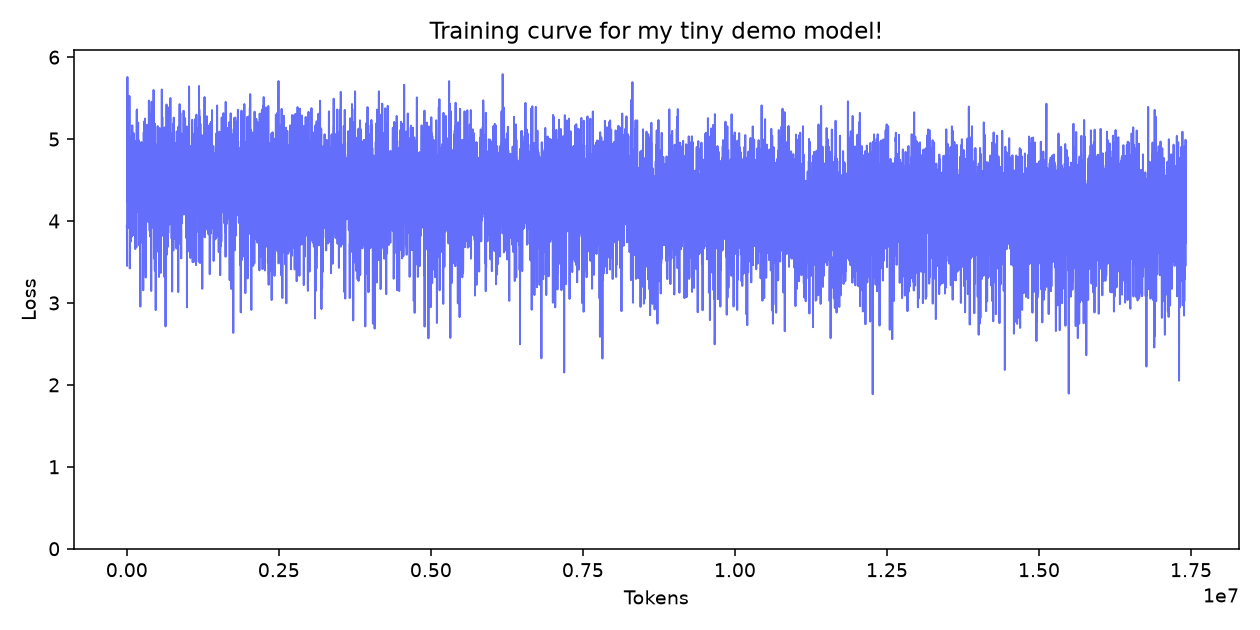

In [ ]:
import matplotlib.pyplot as plt

x = np.arange(len(losses)) * (model_cfg.n_ctx * batch_size)
plt.figure(figsize=(9, 4.5))
plt.plot(x, losses, color="#636efa")
plt.xlabel("Tokens")
plt.ylabel("Loss")
plt.title("Training curve for my tiny demo model!")
plt.ylim(0, max(losses) * 1.05)
plt.tight_layout()
plt.show()

In [75]:
torch.save(model.state_dict(), "tiny_demo_model.pt")